# SCH GradMate: 한국어 졸업요건 RAG 실험 노트북

이 노트북은 실제 학과 제공 자료와 프로젝트의 `src/` 구현을 사용합니다. 실험값은 실행 시 검색 함수가 반환한 결과에서 계산하며, 규정에 없는 값은 만들지 않습니다. 예시 수강 내역은 모두 합성 데이터입니다.

> **2026-11-07 점검·개선 반영 안내.** 이 노트북의 01~19장은 원래 구성을 유지하되, 코드가 바뀐 부분(평가 질문 로딩, Gemini 상태 분류)만 고쳤습니다. **20~26장**이 이번 점검에서 추가된 실험·측정·결론입니다. 원본 노트북은 `SCH_Graduation_RAG.original_2026-11-02.ipynb`, 원래 결과 CSV는 `data/evaluation/results/original_2026-11-02_*.csv` 로 보존되어 있습니다.
>
> **읽는 법:** 01~19장의 일부 서술(예: 문서 수·청크 수)은 코드 실행 결과로 다시 계산되므로 숫자가 이전 실행과 다를 수 있습니다. 서술과 숫자가 다르면 **실행 결과 출력**이 맞습니다.

## 01. 연구 배경 및 프로젝트 목표

대학 졸업요건은 학번·교과 구분·인증 활동에 따라 달라지고, 자료가 여러 문서와 표에 나뉘어 있어 학생이 직접 적용하기 어렵습니다. RAG는 답변 전에 공식 문서의 관련 구절을 찾고 출처를 제시할 수 있어 일반적인 LLM 단독 응답의 근거 부족을 줄이는 데 적합합니다. 다만 RAG가 문서에 없는 조건을 보완하거나 공식 판정을 대신할 수는 없습니다.

**연구 질문:** “검색 기법의 개선이 한국어 대학 졸업요건 질의응답의 정확도에 어떤 영향을 미치는가?”

목표는 문서 처리와 검색 비교, 출처 포함 답변, 규칙 기반 학점·활동 계산을 재현하는 것입니다. 제한점은 이미지 OCR 미적용, 일부 학번 규정의 부재, 공식 과목 목록의 기계 판독 불가입니다.

In [1]:
from pathlib import Path
import sys, json, time, re, unicodedata, statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "app.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"프로젝트 경로: {ROOT}")
print(f"Python: {sys.version.split()[0]}")
print("난수 시드: 42")
np.random.seed(42)
from matplotlib import font_manager
font_names={f.name for f in font_manager.fontManager.ttflist}
korean_font=next((name for name in ("AppleGothic","NanumGothic","Malgun Gothic","Noto Sans CJK KR") if name in font_names),None)
if korean_font:
    plt.rcParams["font.family"]=korean_font
plt.rcParams["axes.unicode_minus"]=False
print("그래프 글꼴:",korean_font or "환경 기본 글꼴")

프로젝트 경로: /Users/linerenza/Desktop/LLM/순천향대 AI빅데이터학과 졸업요건 챗봇
Python: 3.11.15
난수 시드: 42
그래프 글꼴: AppleGothic


## 02. 시스템 구조

규정 설명은 한국어 질문을 FAISS 의미 검색과 BM25 키워드 검색으로 찾고, 하이브리드 점수와 질의어 포함도로 후보를 재정렬한 뒤 Gemini에 근거를 전달하는 RAG 흐름입니다. 학번 필터는 청크의 명시된 학번을 적용하며, 학번이 명시되지 않은 공통 문서는 남깁니다.

과목 학점·세부 분류·비교과 점수는 별도 Python 규칙 엔진에서 계산합니다. RAG는 문서 설명을 돕고, 규칙 엔진은 숫자와 상태를 결정합니다. LLM은 학점을 계산하거나 공식 졸업 승인을 확정하지 않습니다.

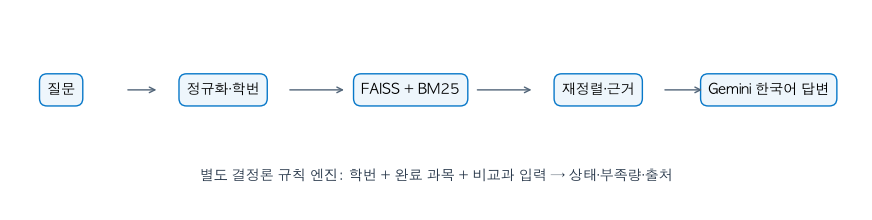

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.axis("off")
boxes=[("질문",.06), ("정규화·학번",.25), ("FAISS + BM25",.47), ("재정렬·근거",.69), ("Gemini 한국어 답변",.89)]
for label,x in boxes:
    ax.text(x,.60,label,ha="center",va="center",bbox=dict(boxstyle="round,pad=.55",fc="#eef6fc",ec="#0878C9"),fontsize=10)
for (_,x1),(_,x2) in zip(boxes,boxes[1:]): ax.annotate("",(x2-.075,.60),(x1+.075,.60),arrowprops=dict(arrowstyle="->",color="#526579"))
ax.text(.5,.15,"별도 결정론 규칙 엔진: 학번 + 완료 과목 + 비교과 입력 → 상태·부족량·출처",ha="center",fontsize=10,color="#243447")
plt.show()

## 03. 데이터셋 구축

`data/documents/`의 모든 문서를 확인하고, 프로젝트의 PyMuPDF 기반 추출·표 처리 함수를 재사용합니다. 스캔 이미지는 생략하지 않고 인식 필요 상태로 요약합니다. PDF의 페이지 수는 원본 파일에서 읽고, 청크 수는 추출 결과에서 셉니다.

In [3]:
from src.document_loader import load_documents, PROJECT_ROOT
import pymupdf
records, extraction_warnings = load_documents()
doc_dir = ROOT / "data" / "documents"
summary=[]
for path in sorted(p for p in doc_dir.iterdir() if p.is_file() and p.name != ".DS_Store"):
    suffix=path.suffix.lower(); pages=None
    if suffix==".pdf":
        with pymupdf.open(path) as pdf: pages=len(pdf)
    related=[r for r in records if unicodedata.normalize("NFC",r["source"])==unicodedata.normalize("NFC",path.name)]
    chars=sum(len(r["text"]) for r in related)
    warnings=[w for w in extraction_warnings if unicodedata.normalize("NFC",path.name) in unicodedata.normalize("NFC",w)]
    summary.append({"문서명":path.name,"형식":suffix,"페이지":pages,"추출 문자":chars,"청크":len(related),"추출 상태":"인식 필요" if warnings else ("텍스트 추출" if related else "내용 없음")})
document_summary=pd.DataFrame(summary)
display(document_summary)
print(f"추출 청크 {len(records)}개 · 경고 {len(extraction_warnings)}건")
for warning in extraction_warnings: print("-",warning)

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


,문서명,형식,페이지,추출 문자,청크,추출 상태
0,2024학번 졸업요건.jpeg,.jpeg,NaN,150,1,텍스트 추출
1,AI·빅데이터학과_20240305.pdf,.pdf,1.0,1160,5,텍스트 추출
2,AI빅데이터학과 졸업여건.png,.png,NaN,1712,7,텍스트 추출
3,AI빅데이터학과 교육과정.pdf,.pdf,2.0,1457,9,텍스트 추출
4,다면적졸업인증제 비교과 배점 기준표.pdf,.pdf,6.0,15673,24,텍스트 추출
5,봉사활동 등록 가이드라인 및 자주묻는ᄌ...,.pdf,10.0,4822,22,인식 필요
6,졸업자격요건.png,.png,NaN,605,9,텍스트 추출
7,학과 봉사학습 지도 가이드라인(조교ver).pdf,.pdf,10.0,5523,22,텍스트 추출


추출 청크 99개 · 경고 1건
- 봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf 6쪽: 이미지 또는 스캔 페이지로 확인되어 문서 인식(OCR)이 필요합니다.


## 04. 데이터 전처리 및 청킹

공유 문서 처리기는 PDF의 텍스트·표와 TXT·Markdown을 페이지·문단 단위로 나눕니다. 기본 설정은 문자 기준 최대 1,100자, 겹침 120자이며 줄 경계를 우선 보존합니다. 각 청크에는 출처, 쪽수, 범주, 명시적으로 추출된 학번 정보가 남습니다. 작은 청크는 검색 범위가 정밀할 수 있지만 문맥이 짧고, 큰 청크는 문맥을 보존하지만 무관한 내용이 함께 들어갈 수 있습니다.

아래 표본 비교는 설정별 **문자 창 개수의 근사치**입니다. 실제 청킹은 문단·학번 표 경계를 보존하므로 이 근사값과 다를 수 있습니다.

In [4]:
chunks_df=pd.DataFrame([{**r,"chunk_id":f"{r['source']}::p{r['page']}::c{i:03d}"} for i,r in enumerate(records)])
display(chunks_df[["chunk_id","source","page","admission_year","admission_years","category","text"]].head(8))
from src.document_loader import CHUNK_SIZE, OVERLAP
sample_text="\n".join(r["text"] for r in records[:4])
def estimate_windows(char_count,size,overlap):
    return 1 if char_count<=size else 1+int(np.ceil((char_count-size)/(size-overlap)))
chunk_experiment=pd.DataFrame([{"설정":"작은 청크(가상)","최대 문자":600,"겹침 문자":80,"근사 창 수":estimate_windows(len(sample_text),600,80)},{"설정":"현재 구현","최대 문자":CHUNK_SIZE,"겹침 문자":OVERLAP,"근사 창 수":estimate_windows(len(sample_text),CHUNK_SIZE,OVERLAP)}])
display(chunk_experiment)
print(f"실제 구현 기본값: {CHUNK_SIZE}자, 겹침 {OVERLAP}자. 표의 창 수는 문자 창 근사치이며 실제 줄·문단 경계 청크 수와 다를 수 있습니다.")

,chunk_id,source,page,admission_year,admission_years,category,text
0,AI·빅데이터학과_20240305.pdf::p1::c000,AI·빅데이터학과_20240305.pdf,1,NaN,"[2017, 2018]",학과자료,2017 ~ 2018 | 점수소계 | 45 | 10 | 9 | 16 | 80\n |...
1,AI·빅데이터학과_20240305.pdf::p1::c001,AI·빅데이터학과_20240305.pdf,1,NaN,"[2019, 2020]",학과자료,2019 ~ 2020 | 점수소계 | 45 | 5 | 11 | 19 | 80\n |...
2,AI·빅데이터학과_20240305.pdf::p1::c002,AI·빅데이터학과_20240305.pdf,1,2021.0,[2021],학과자료,2021 | 점수소계 | 45 | 5 | 11 | 19 | 80\n | 소통하는 공...
3,AI·빅데이터학과_20240305.pdf::p1::c003,AI·빅데이터학과_20240305.pdf,1,2022.0,[2022],학과자료,2022 | 점수소계 | 45 | 10 | 21 | 19 | 95\n | 소통하는 ...
4,AI·빅데이터학과_20240305.pdf::p1::c004,AI·빅데이터학과_20240305.pdf,1,NaN,"[2023, 2024]",학과자료,2023 ~ 2024 | 점수소계 | 45 | 5 | 26 | 19 | 95\n |...
5,다면적졸업인증제 비교과 배점 기준표.pdf::p1::c005,다면적졸업인증제 비교과 배점 기준표.pdf,1,NaN,None,졸업요건,중분류 | 소분류 | 세부항목(예시) | 인재상 (점수) | 역량점수 승인기준 | ...
6,다면적졸업인증제 비교과 배점 기준표.pdf::p1::c006,다면적졸업인증제 비교과 배점 기준표.pdf,1,NaN,None,졸업요건,"동아리 | ASP | 활동계획서, 보고서 제출 | 공감(5) | 1, 2학기 | A..."
7,다면적졸업인증제 비교과 배점 기준표.pdf::p1::c007,다면적졸업인증제 비교과 배점 기준표.pdf,1,NaN,None,졸업요건,다면적졸업인증제 비교과 배점 기준표\n(2024. 3. 1 기준)\n인재상 역량점수...


,설정,최대 문자,겹침 문자,근사 창 수
0,작은 청크(가상),600,80,2
1,현재 구현,1100,120,1


실제 구현 기본값: 1100자, 겹침 120자. 표의 창 수는 문자 창 근사치이며 실제 줄·문단 경계 청크 수와 다를 수 있습니다.


## 05. 한국어 임베딩

임베딩은 문장을 벡터로 바꾸어 어휘가 달라도 의미가 가까운 문장을 비교하게 합니다. 프로젝트는 `paraphrase-multilingual-MiniLM-L12-v2`를 문서와 질의에 함께 사용합니다. 벡터를 L2 정규화하면 내적과 코사인 유사도가 같습니다.

\[
\operatorname{sim}(a,b)=\frac{a\cdot b}{\|a\|\,\|b\|}
\]

코사인 유사도는 방향의 유사성을 비교하며 값이 클수록 의미가 가까운 것으로 해석합니다. 다국어 모델은 한국어를 처리하지만, 학과 고유 용어·표의 숫자 관계를 항상 정확히 이해하는 것은 아닙니다.

In [5]:
from src.retrieval import embedder, MODEL
model=embedder()
sentences=["2024학번은 총 몇 학점을 이수해야 하나요?","2024학번 졸업 총 이수학점 기준","봉사학습 자율봉사 신청 절차"]
vectors=model.encode(sentences,normalize_embeddings=True,show_progress_bar=False)
print("모델:",MODEL,"· 임베딩 차원:",vectors.shape[1])
similarity=vectors @ vectors.T
display(pd.DataFrame(similarity,index=sentences,columns=sentences).round(3))

/Users/linerenza/Desktop/LLM/순천향대 AI빅데이터학과 졸업요건 챗봇/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1107 18:19:59.559000 24662 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8053.98it/s]

모델: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 · 임베딩 차원: 384


,2024학번은 총 몇 학점을 이수해야 하나요?,2024학번 졸업 총 이수학점 기준,봉사학습 자율봉사 신청 절차
2024학번은 총 몇 학점을 이수해야 하나요?,1.000,0.758,0.142
2024학번 졸업 총 이수학점 기준,0.758,1.000,0.237
봉사학습 자율봉사 신청 절차,0.142,0.237,1.000


## 06. FAISS 밀집 검색

문서 임베딩을 FAISS `IndexFlatIP`에 저장하고 정규화된 질의 벡터와 내적을 비교합니다. 정규화가 적용되어 내적 값은 코사인 유사도입니다. 이 인덱스는 전체 벡터를 비교하는 정확 검색으로 작은 문서 모음에 단순하고 재현 가능하지만, 문서 수가 커지면 계산 비용이 증가합니다. 검색 시 학번 불일치 청크는 결과에서 제외합니다.

In [6]:
from src.retrieval import index, dense_search
records, faiss_index, bm25_index, index_warnings=index()
question="2024학번 졸업요건은 무엇인가요?"
dense_hits=dense_search(question,year=2024,limit=5)
display(pd.DataFrame([{"순위":i+1,"점수":round(h["score"],4),"문서":h["source"],"쪽":h["page"],"내용":h["text"][:240]} for i,h in enumerate(dense_hits)]))

,순위,점수,문서,쪽,내용
0,1,0.7550,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
1,2,0.7516,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
2,3,0.6659,2024학번 졸업요건.jpeg,1,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
3,4,0.5913,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 4학년: 졸업논문 심의에 통과하여야...
4,5,0.5804,AI·빅데이터학과_20240305.pdf,1,2023 ~ 2024 | 점수소계 | 45 | 5 | 26 | 19 | 95\n |...


## 07. BM25 희소 검색

BM25는 질의 토큰이 문서에서 얼마나 자주 나타나는지와 문서 길이를 고려하는 어휘 기반 순위화입니다. 구현은 `rank_bm25.BM25Okapi`를 사용하며, 한글 문자열 토큰과 2-그램을 추가해 조사·복합어 표기의 일부 차이를 보완합니다.

\[
\operatorname{BM25}(q,d)=\sum_{t\in q} IDF(t)\cdot
\frac{f(t,d)(k_1+1)}{f(t,d)+k_1(1-b+b\cdot |d|/\operatorname{avgdl})}
\]

공식 용어·숫자와 같은 정확한 표현에 강하지만 동의어·문장 의미만 비슷한 질문에는 밀집 검색보다 불리할 수 있습니다.

In [7]:
from src.retrieval import bm25_search, tokenize
bm25_hits=bm25_search(question,year=2024,limit=5)
print("질의 토큰 예시:",tokenize(question)[:20])
display(pd.DataFrame([{"순위":i+1,"점수":round(h["score"],4),"문서":h["source"],"쪽":h["page"],"내용":h["text"][:240]} for i,h in enumerate(bm25_hits)]))

질의 토큰 예시: ['2024', '학번', '졸업요건은', '무엇인가요', '졸업', '업요', '요건', '건은', '무엇', '엇인', '인가', '가요']


,순위,점수,문서,쪽,내용
0,1,18.3485,2024학번 졸업요건.jpeg,1,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
1,2,4.9515,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
2,3,4.8348,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
3,4,4.7175,졸업자격요건.png,1,졸업자격요건 표(학과명이 표기되지 않은 자료). 졸업학점: 130학점 이상. 적용 ...
4,5,4.6566,AI빅데이터학과 졸업여건.png,1,다면적 졸업인증제 1. 대학공통 필수 (2024~2026학번). 소통하는 공감인재:...


## 08. 하이브리드 검색

**구현 설명:** 현재 `src/retrieval.py`의 하이브리드 방식은 Reciprocal Rank Fusion(RRF)이 아닙니다. BM25 점수를 학번 허용 문서 중 최댓값으로 나누고, 의미 유사도를 0.30~0.75 구간에서 0~1로 제한한 뒤 가중 합산합니다.

\[
S(d)=0.62\,\widetilde{BM25}(d)+0.38\,\operatorname{clip}\left(\frac{\cos(d,q)-0.30}{0.45},0,1\right)
\]

후보는 BM25 점수가 양수이거나 의미 유사도가 0.66 이상인 청크이며, 질문 의도에 따라 핵심 용어가 없는 후보를 더 걸러냅니다. 서로 다른 원점수의 직접 합산 대신 정규화한 점수를 쓰는 장점이 있지만, 가중치와 임계값은 현재 휴리스틱이므로 평가셋 밖에서 재조정이 필요합니다.

In [8]:
from src.retrieval import search
hybrid_hits,_=search(question,year=2024,limit=5)
def result_table(method, hits):
    return [{"방법":method,"순위":i+1,"문서":h["source"],"쪽":h["page"],"점수":round(float(h.get("score",0)),4),"내용":h["text"][:180]} for i,h in enumerate(hits)]
display(pd.DataFrame(result_table("BM25",bm25_hits)+result_table("FAISS",dense_hits)+result_table("하이브리드",hybrid_hits)))

,방법,순위,문서,쪽,점수,내용
0,BM25,1,2024학번 졸업요건.jpeg,1,18.3485,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
1,BM25,2,졸업자격요건.png,1,4.9515,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
2,BM25,3,졸업자격요건.png,1,4.8348,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
3,BM25,4,졸업자격요건.png,1,4.7175,졸업자격요건 표(학과명이 표기되지 않은 자료). 졸업학점: 130학점 이상. 적용 ...
4,BM25,5,AI빅데이터학과 졸업여건.png,1,4.6566,다면적 졸업인증제 1. 대학공통 필수 (2024~2026학번). 소통하는 공감인재:...
5,FAISS,1,졸업자격요건.png,1,0.7550,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
6,FAISS,2,졸업자격요건.png,1,0.7516,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
7,FAISS,3,2024학번 졸업요건.jpeg,1,0.6659,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
8,FAISS,4,졸업자격요건.png,1,0.5913,졸업자격요건 표(학과명이 표기되지 않은 자료). 4학년: 졸업논문 심의에 통과하여야...
9,FAISS,5,AI·빅데이터학과_20240305.pdf,1,0.5804,2023 ~ 2024 | 점수소계 | 45 | 5 | 26 | 19 | 95\n |...


## 09. 재정렬

재정렬은 하이브리드 상위 후보를 질의 토큰 포함률에 따라 다시 정렬합니다. 구현 점수는 하이브리드 점수 70%, 질의 토큰 본문 포함률 30%입니다.

\[
S_{rerank}(d)=0.7S_{hybrid}(d)+0.3\frac{\text{질의 토큰 중 본문에 포함된 수}}{\text{고유 질의 토큰 수}}
\]

별도 학습된 교차 인코더가 아닌 규칙 기반 재정렬이므로, 의미적 관련성 향상을 보장하지 않습니다. 아래 결과와 평가 지표에서 실제 효과를 확인합니다.

In [9]:
from src.retrieval import rerank_results
reranked_hits=rerank_results(question,hybrid_hits,limit=5)
display(pd.DataFrame(result_table("하이브리드",hybrid_hits)+[{"방법":"하이브리드+재정렬","순위":i+1,"문서":h["source"],"쪽":h["page"],"점수":round(float(h.get("rerank_score",0)),4),"내용":h["text"][:180]} for i,h in enumerate(reranked_hits)]))

,방법,순위,문서,쪽,점수,내용
0,하이브리드,1,2024학번 졸업요건.jpeg,1,0.9290,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
1,하이브리드,2,졸업자격요건.png,1,0.5473,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
2,하이브리드,3,졸업자격요건.png,1,0.5434,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
3,하이브리드,4,졸업자격요건.png,1,0.4002,졸업자격요건 표(학과명이 표기되지 않은 자료). 4학년: 졸업논문 심의에 통과하여야...
4,하이브리드,5,졸업자격요건.png,1,0.3777,졸업자격요건 표(학과명이 표기되지 않은 자료). 졸업학점: 130학점 이상. 적용 ...
5,하이브리드+재정렬,1,2024학번 졸업요건.jpeg,1,0.7753,AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점)...
6,하이브리드+재정렬,2,졸업자격요건.png,1,0.4581,졸업자격요건 표(학과명이 표기되지 않은 자료). 교양: 32학점 이수 (2019~2...
7,하이브리드+재정렬,3,졸업자격요건.png,1,0.4554,졸업자격요건 표(학과명이 표기되지 않은 자료). 학과기초: 22학점 이수 (2016...
8,하이브리드+재정렬,4,졸업자격요건.png,1,0.3552,졸업자격요건 표(학과명이 표기되지 않은 자료). 4학년: 졸업논문 심의에 통과하여야...
9,하이브리드+재정렬,5,졸업자격요건.png,1,0.3394,졸업자격요건 표(학과명이 표기되지 않은 자료). 졸업학점: 130학점 이상. 적용 ...


## 10. Gemini 기반 RAG

공유 `gemini_answer` 함수는 `.env`의 `GEMINI_API_KEY`와 `GEMINI_MODEL`을 읽으며 검색 근거에 출처명·쪽수·학번 메타데이터를 붙입니다. 프롬프트는 문서 내용을 지시문이 아닌 참고 자료로 취급하도록 요구합니다. 키나 모델이 없거나 API 호출이 실패하면 검색 실험은 계속하고 한국어 안내를 표시합니다. 키 값은 출력하지 않습니다.

In [10]:
from dotenv import load_dotenv
import os
load_dotenv(ROOT/".env")
print("Gemini 키 설정:",bool(os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY")),"· 모델 설정:",bool(os.getenv("GEMINI_MODEL")))
from src.rag import gemini_answer
rag_question="2024학번 졸업학점은 몇 학점인가요?"
rag_answer,rag_passages,rag_warnings=gemini_answer(rag_question,2024)
print("질문:",rag_question)
print("근거 수:",len(rag_passages))
print(rag_answer)
print("검색 경고:",rag_warnings[:5])

Gemini 키 설정: True · 모델 설정: True


질문: 2024학번 졸업학점은 몇 학점인가요?
근거 수: 4
Gemini 응답을 받지 못해 검색 근거 기반으로 안내드립니다.

제공된 자료에서 확인한 내용입니다.

- **2024학번 졸업요건 1쪽 · 2024학번**
  > AI·빅데이터학과 2024학번 졸업요건(교육과정 이수조건): 졸업학점(총 이수학점) 130학점.
  > 전공 76학점(전공기초 28, 전공필수 0, 전공선택 48), 교양 32학점(교양공통 12, 교양영역 9, 교양선택 11).
  > 전공필수 0학점.
  > 다면적 졸업인증 기준 95점.
- **졸업자격요건 (학과명 미표기) 1쪽**
  > 졸업자격요건 표(학과명이 표기되지 않은 자료).
  > 졸업학점: 130학점 이상.
- **졸업자격요건 (학과명 미표기) 1쪽 · 2019~2025학번**
  > 졸업자격요건 표(학과명이 표기되지 않은 자료).
  > 교양: 32학점 이수 (2019~2025학번).

※ 이 자료에는 적용 학번이 명시되어 있지 않습니다. 본인 학번에 그대로 적용되는지 학과 사무실에서 확인해 주세요.

출처: 2024학번 졸업요건.jpeg 1쪽
출처: 졸업자격요건.png 1쪽
검색 경고: ['봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf 6쪽: 이미지 또는 스캔 페이지로 확인되어 문서 인식(OCR)이 필요합니다.', 'Gemini 답변 생성 서비스가 응답하지 않아 검색 근거 기반으로 안내했습니다. (오류 코드 503)']


## 11. 졸업요건 규칙 엔진

학점·세부 분류·비교과 기준은 결정론 Python 함수로 계산합니다. LLM은 계산 과정에서 숫자를 만들거나 공식 졸업 승인을 확정하지 않습니다. 제공 자료에 없는 기준은 `확인 필요`로 표시합니다. 아래 예시는 합성 점수 입력입니다.

In [11]:
from src.graduation_checker import check_credits, check_graduation_requirements
synthetic_totals={"total":108,"major":58,"general":32,"detail_totals":{},"subcategory_unclassified_credits":{"major":58,"general":32}}
rule_rows=check_credits(2024,synthetic_totals)
display(pd.DataFrame(rule_rows))
rule_detail=check_graduation_requirements(2024,synthetic_totals)
print("공식 확정:",rule_detail["official_determination"])
display(pd.DataFrame(rule_detail["requirements"])[["name","status"]])

,name,status,current,required,missing,detail,source
0,총 이수학점,미충족,108.0,130.0,22.0,,"{'document': '2024학번 졸업요건.jpeg', 'page': 1}"
1,전공 이수학점,미충족,58.0,76.0,18.0,,"{'document': '2024학번 졸업요건.jpeg', 'page': 1}"
2,교양 이수학점,충족,32.0,32.0,0.0,,"{'document': '2024학번 졸업요건.jpeg', 'page': 1}"


공식 확정: False


,name,status
0,총 이수학점,미충족
1,전공 이수학점,미충족
2,교양 이수학점,충족
3,전공기초,확인 필요
4,전공필수 학점,확인 필요
5,전공선택,확인 필요
6,교양공통,확인 필요
7,교양영역,확인 필요
8,교양선택,확인 필요
9,전공필수 과목 목록,확인 필요


## 12. 수강과목 업로드 및 활동 분석

합성 과목표를 같은 CSV 파서에 전달해 정규화, 중복 제거, 완료 학점 계산을 확인합니다. 비교과 점수도 학번별 JSON 규칙을 적용합니다. 입력된 실적과 승인 점수는 별개이며, 자동 계산은 학생 보고값을 공식 승인으로 간주하지 않습니다.

In [12]:
from io import BytesIO
from src.course_parser import parse_courses, credit_totals
from src.activity_checker import calculate_activity_points
from src.graduation_checker import check_graduation_eligibility
synthetic_csv="course_name,credits,category,status\n선형대수학,3,전공,completed\n선형 대수학,3,전공,재수강완료\n현대기본영어,5,교양,completed\n현재수강,3,전공,in_progress\n".encode()
courses,course_warnings=parse_courses(synthetic_csv,"synthetic_courses.csv")
totals=credit_totals(courses)
print("합성 수강과목 점수:",totals)
print("검증 안내:",course_warnings)
activity=calculate_activity_points(2024,{"TOPCIT 응시":2,"경진대회 참가":1})
print("합성 비교과 입력:",activity["estimated_points"],"점 · 상태:",activity["status"])
combined=check_graduation_eligibility(2024,courses,{"selections":{"TOPCIT 응시":2,"경진대회 참가":1}})
print("통합 결과 상태:",combined["overall_status"],"· 공식 판정:",combined["official_determination"])
display(pd.DataFrame(combined["requirements"])[["name","status"]])

합성 수강과목 점수: {'total': 8.0, 'major': 3.0, 'general': 5.0, 'completed_courses': 2, 'in_progress_courses': 1, 'invalid_courses': 0, 'duplicate_courses': 1, 'uncategorized_credits': 0.0, 'subcategory_unclassified_credits': {'major': 3.0, 'general': 5.0}, 'category_totals': {'general': 5.0, 'major': 3.0}, 'detail_totals': {}}
검증 안내: ['2행: 같은 교과목이 중복되어 한 번만 학점에 반영합니다.', '3행: 재수강 과목의 학점 인정 여부를 확인해야 합니다. 같은 교과목이 중복되어 한 번만 학점에 반영합니다.', '중복·재수강 가능 과목은 성적표와 학사 기준에서 확인해 주세요.']
합성 비교과 입력: 2.0 점 · 상태: 미충족
통합 결과 상태: 확인 필요 · 공식 판정: False


,name,status
0,총 이수학점,미충족
1,전공 이수학점,미충족
2,교양 이수학점,미충족
3,전공기초,확인 필요
4,전공필수 학점,확인 필요
5,전공선택,확인 필요
6,교양공통,확인 필요
7,교양영역,확인 필요
8,교양선택,확인 필요
9,전공필수 과목 목록,확인 필요


## 13. 평가 질의 데이터셋

`data/evaluation/questions.json`에는 출처 페이지와 사람이 확인한 기대 사실을 갖는 30개 한국어 질문이 있습니다. 지원되지 않는 기준과 지식베이스 범위 밖 질문도 포함합니다. 아래 검사는 중복 ID·질문, 빈 라벨, 출처 페이지 부재, 사용할 수 없는 학번, 인덱스 청크 불일치를 찾습니다.

**2026-11-07 갱신:** 평가 질문을 30개에서 60개로 늘렸습니다(원본 30개는 `questions_v1_original.json`에 보존). 학번 미지정(되묻기)·충돌 자료·학번 혼용 함정·계산·미지원·프롬프트 주입 질문을 추가했고, 청크 ID는 안정 ID로 바꿨습니다. 라벨 수정 내역은 각 질문의 `label_revision` 필드에 기록되어 있습니다.

In [13]:
eval_path=ROOT/"data/evaluation/questions.json"
evaluation_questions=json.loads(eval_path.read_text(encoding="utf-8"))
ids=[q["question_id"] for q in evaluation_questions]
assert len(ids)==len(set(ids)),"중복 질문 ID"
# 같은 문장이라도 학번이 다르면 다른 평가 항목입니다(학번 미지정/지정 비교).
keys=[(q["question"],q["admission_year"]) for q in evaluation_questions]
assert len(keys)==len(set(keys)),"중복 질문(문장+학번)"
# 사실 라벨은 '정상 답변이 기대되는' 질문에만 필요합니다(학번 되묻기·미지원·주입 질문은 사실이 없을 수 있음).
needs_facts=[q for q in evaluation_questions if q["answerable"] and q.get("expected_behavior","answer") not in ("clarify_year","no_year_mixing")]
assert all(q["expected_answer_facts"] for q in needs_facts) and all(isinstance(q["answerable"],bool) for q in evaluation_questions),"빈 평가 라벨"
year_buckets={"2019-2021":set(range(2019,2022)),"2022":{2022},"2023-2026":set(range(2023,2027)),"2024":{2024}}
known_years=set().union(*year_buckets.values())
assert all(q["admission_year"] is None or q["admission_year"] in known_years for q in evaluation_questions)
# 청크 ID 는 src.document_loader 가 부여한 안정 ID(chunk_id)를 사용합니다. 라벨이 현재 청킹과 맞는지 검증만 하고 파일은 다시 쓰지 않습니다.
record_lookup={}
for r in records: record_lookup.setdefault((unicodedata.normalize("NFC",r["source"]),r["page"]),[]).append(r["chunk_id"])
for q in evaluation_questions:
    for ref in q["relevant_sources"]:
        assert (unicodedata.normalize("NFC",ref["source"]),ref["page"]) in record_lookup,f"유효하지 않은 출처: {ref}"
        assert set(ref["chunk_ids"])<=set(record_lookup[(unicodedata.normalize("NFC",ref["source"]),ref["page"])]),f"청크 ID 불일치: {q['question_id']}"
kinds=pd.Series([q.get("question_type","factual") for q in evaluation_questions]).value_counts()
print("평가 질문:",len(evaluation_questions),"· 답변 가능:",sum(q["answerable"] for q in evaluation_questions),"· 미지원:",sum(not q["answerable"] for q in evaluation_questions))
print("질문 유형:",dict(kinds))
display(pd.DataFrame(evaluation_questions)[["question_id","category","question","admission_year","answerable"]].head(10))

평가 질문: 60 · 답변 가능: 52 · 미지원: 8
질문 유형: {'factual': np.int64(46), 'unanswerable': np.int64(5), 'ambiguous_year': np.int64(3), 'conflicting': np.int64(2), 'calculation': np.int64(1), 'year_trap': np.int64(1), 'out_of_scope': np.int64(1), 'injection': np.int64(1)}


,question_id,category,question,admission_year,answerable
0,Q01,학점,2024학번의 총 졸업 이수학점은 몇 학점인가요?,2024.0,True
1,Q02,학점,2024학번 전공 이수학점 기준은 얼마인가요?,2024.0,True
2,Q03,학점,2024학번 교양 이수학점은 몇 학점인가요?,2024.0,True
3,Q04,학점,2024학번 전공기초 이수 기준은 몇 학점인가요?,2024.0,True
4,Q05,학점,2024학번 전공선택 이수 기준은 몇 학점인가요?,2024.0,True
5,Q06,학점,2024학번 교양공통 기준은 몇 학점인가요?,2024.0,True
6,Q07,학점,2024학번 교양영역 기준은 몇 학점인가요?,2024.0,True
7,Q08,학점,2024학번 교양선택 기준은 몇 학점인가요?,2024.0,True
8,Q09,전공,2024학번 전공필수 이수 학점은 몇 학점으로 표시되어 있나요?,2024.0,True
9,Q10,비교과,2024학번 다면적 졸업인증 점수 소계는 얼마인가요?,2024.0,True


## 14. 검색 평가

관련성 라벨은 평가 JSON의 관련 **문서·쪽** 쌍이며 같은 쪽의 청크를 같은 관련 결과로 취급합니다. 지원 가능 질의에 대해 Recall@3/5, MRR@5, Hit Rate@5와 호출 지연을 계산합니다.

\[
Recall@k=\frac{|G_q\cap R_{q,k}|}{|G_q|},\qquad
MRR@5=\frac{1}{|Q|}\sum_{q\in Q}\frac{1}{rank_q}
\]

여기서 \(G_q\)는 질문별 정답 문서·쪽 집합, \(R_{q,k}\)는 상위 \(k\) 결과이고, 상위 5개에 관련 결과가 없으면 해당 질문의 역순위는 0입니다. Hit Rate@5는 질문별로 관련 문서·쪽이 하나라도 상위 5개에 있는지 계산합니다. 지연은 색인 로딩 이후 한 번의 검색 호출 시간으로 측정합니다.

**라벨 범위:** 관련성은 평가 파일에 미리 지정한 문서·쪽 쌍에 대한 판정입니다. 모든 관련 페이지를 빠짐없이 지정했다는 보장은 없으므로 Recall은 이 라벨 집합에 대한 조건부 지표입니다.

In [14]:
from src.retrieval import dense_search,bm25_search,search,rerank_results
import time

def relevant_keys(q): return {(unicodedata.normalize("NFC",x["source"]),x["page"]) for x in q["relevant_sources"]}
def hit_keys(hits): return [(unicodedata.normalize("NFC",h["source"]),h["page"]) for h in hits]
def score_query(q,method,hits,latency):
    relevant=relevant_keys(q); ranked=hit_keys(hits); rel=[k in relevant for k in ranked]
    def recall(k): return len(set(ranked[:k]) & relevant)/len(relevant) if relevant else np.nan
    rr=next((1/(i+1) for i,v in enumerate(rel[:5]) if v),0.0)
    return {"질의 ID":q["question_id"],"방법":method,"Recall@3":recall(3),"Recall@5":recall(5),"MRR@5":rr,"Hit Rate@5":float(any(rel[:5])),"지연시간(초)":latency}

metric_rows=[]
answerable=[q for q in evaluation_questions if q["answerable"] and q["relevant_sources"]]
for q in answerable:
    for method,fn in [("BM25",lambda q:bm25_search(q["question"],q["admission_year"],5)),("FAISS",lambda q:dense_search(q["question"],q["admission_year"],5)),("하이브리드",lambda q:search(q["question"],q["admission_year"],5)[0])]:
        t=time.perf_counter(); hits=fn(q); elapsed=time.perf_counter()-t
        metric_rows.append(score_query(q,method,hits,elapsed))
    t=time.perf_counter(); base,_=search(q["question"],q["admission_year"],10); reranked=rerank_results(q["question"],base,5); elapsed=time.perf_counter()-t
    metric_rows.append(score_query(q,"하이브리드+재정렬",reranked,elapsed))
metric_detail=pd.DataFrame(metric_rows)
metric_summary=metric_detail.groupby("방법",as_index=False).agg({"Recall@3":"mean","Recall@5":"mean","MRR@5":"mean","Hit Rate@5":"mean","지연시간(초)":"mean"})
result_dir=ROOT/"data/evaluation/results"; result_dir.mkdir(parents=True,exist_ok=True)
metric_detail.to_csv(result_dir/"retrieval_metrics.csv",index=False)
display(metric_summary.round(4))
print(f"실제 평가 질의 수: {len(answerable)} · 결과 행: {len(metric_detail)}")
comparison=metric_summary.set_index("방법")
print(f"하이브리드 Recall@5는 FAISS보다 {comparison.loc['하이브리드','Recall@5']-comparison.loc['FAISS','Recall@5']:+.3f}, BM25보다 {comparison.loc['하이브리드','Recall@5']-comparison.loc['BM25','Recall@5']:+.3f}입니다.")
print(f"재정렬 MRR@5 변화(하이브리드 대비): {comparison.loc['하이브리드+재정렬','MRR@5']-comparison.loc['하이브리드','MRR@5']:+.3f}.")

,방법,Recall@3,Recall@5,MRR@5,Hit Rate@5,지연시간(초)
0,BM25,0.8038,0.9000,0.8782,1.0000,0.0005
1,FAISS,0.5125,0.6173,0.5760,0.7500,0.0158
2,하이브리드,0.8090,0.9176,0.8910,1.0000,0.0146
3,하이브리드+재정렬,0.7981,0.8872,0.8910,0.9808,0.0150


실제 평가 질의 수: 52 · 결과 행: 208
하이브리드 Recall@5는 FAISS보다 +0.300, BM25보다 +0.018입니다.
재정렬 MRR@5 변화(하이브리드 대비): +0.000.


## 15. RAG 답변 평가

대표 질문 4개에 대해 Gemini RAG를 호출하고 인용 페이지·학번 필터·한국어 여부를 자동 점검합니다. API 실패 시 대체 응답과 실패 상태를 CSV에 기록합니다. 사실 정확성과 환각 여부는 모델 자기평가로 점수화하지 않고 사람이 검토하도록 미평가로 둡니다. 자동 출처 검사는 제한적인 proxy이며 의미적 정답 판정과 같지 않습니다.

In [15]:
from src.rag import gemini_answer, INSUFFICIENT
sample_ids={"Q01","Q10","Q18","Q30"}
answer_rows=[]
for q in [row for row in evaluation_questions if row["question_id"] in sample_ids]:
    text,hits,warnings=gemini_answer(q["question"],q["admission_year"])
    skipped=text.startswith("Gemini 답변 생성을 건너뜁니다")  # 키/모델 미설정
    api_failed=skipped or text.startswith("Gemini 응답을 받지 못해") or any("Gemini 답변 생성 서비스가 응답하지 않아" in w for w in warnings)
    retrieved={(unicodedata.normalize("NFC",h["source"]),h["page"]) for h in hits}
    expected=relevant_keys(q)
    citation_ok=(bool(retrieved & expected) if q["answerable"] and expected else (not hits and not q["answerable"]))
    unsupported_ok=(INSUFFICIENT in text if not q["answerable"] else None)
    year_ok=(all(h.get("admission_years") is None or q["admission_year"] is None or q["admission_year"] in h.get("admission_years",[]) for h in hits) if q["admission_year"] else None)
    answer_rows.append({"질의 ID":q["question_id"],"생성 상태":"미설정(건너뜀)" if skipped else "검색 기반 대체" if api_failed else ("근거 없음 안내" if not hits else "Gemini 응답 수신"),"사실 정확성":"미평가: 실제 Gemini 응답 없음" if api_failed else "수동 검토 필요","근거 페이지 일치(자동)":citation_ok,"인용 정확성(자동)":citation_ok,"학번 필터(자동)":year_ok,"미지원 응답(자동)":unsupported_ok,"환각 회피":"미평가: 실제 Gemini 응답 없음" if api_failed else "수동 검토 필요","한국어 응답":bool(re.search(r"[가-힣]",text)),"답변 미리보기":text[:260],"오류 경고":" | ".join(w for w in warnings if "Gemini" in w)})
answer_evaluation=pd.DataFrame(answer_rows)
answer_evaluation.to_csv(result_dir/"answer_evaluation.csv",index=False)
display(answer_evaluation[["질의 ID","생성 상태","사실 정확성","인용 정확성(자동)","학번 필터(자동)","한국어 응답","오류 경고"]])
print("자동 출처·학번 검사는 제한된 proxy입니다. 사실 정확성·환각 여부는 실제 Gemini 답변을 얻은 뒤 사람이 평가해야 합니다.")

,질의 ID,생성 상태,사실 정확성,인용 정확성(자동),학번 필터(자동),한국어 응답,오류 경고
0,Q01,검색 기반 대체,미평가: 실제 Gemini 응답 없음,True,True,True,Gemini 답변 생성 서비스가 응답하지 않아 검색 근거 기반으로 안내했습니다. (...
1,Q10,검색 기반 대체,미평가: 실제 Gemini 응답 없음,True,True,True,Gemini 답변 생성 서비스가 응답하지 않아 검색 근거 기반으로 안내했습니다. (...
2,Q18,검색 기반 대체,미평가: 실제 Gemini 응답 없음,True,None,True,Gemini 답변 생성 서비스가 응답하지 않아 검색 근거 기반으로 안내했습니다. (...
3,Q30,근거 없음 안내,수동 검토 필요,True,None,True,


자동 출처·학번 검사는 제한된 proxy입니다. 사실 정확성·환각 여부는 실제 Gemini 답변을 얻은 뒤 사람이 평가해야 합니다.


## 16. 기준선 및 제거 실험

Gemini 무검색, 밀집 RAG, 하이브리드 RAG, 재정렬 RAG를 동일 생성 조건으로 비교하려면 각 방식의 별도 프롬프트와 반복 API 호출이 필요합니다. 이 프로젝트에는 Gemini 기반 검색 응답만 구현되어 있고 무검색 생성 실험은 아직 독립 구현·실행되지 않았습니다. 한 번의 RAG 시연으로 비교 성능을 주장하지 않습니다.

In [16]:
hybrid_attempts=int(answer_evaluation["생성 상태"].isin(["Gemini 응답 수신","검색 기반 대체"]).sum())
hybrid_success=int((answer_evaluation["생성 상태"]=="Gemini 응답 수신").sum())
ablation=pd.DataFrame([
 {"조건":"Gemini 무검색","실행 상태":"미구현·미실행","정확도":np.nan,"근거성":np.nan,"인용 정확도":np.nan,"응답 지연(초)":np.nan},
 {"조건":"Gemini + FAISS","실행 상태":"별도 생성 실험 미실행","정확도":np.nan,"근거성":np.nan,"인용 정확도":np.nan,"응답 지연(초)":np.nan},
 {"조건":"Gemini + 하이브리드","실행 상태":f"{hybrid_attempts}회 시도, {hybrid_success}회 생성 성공","정확도":np.nan,"근거성":np.nan,"인용 정확도":np.nan,"응답 지연(초)":np.nan},
 {"조건":"Gemini + 하이브리드 + 재정렬","실행 상태":"별도 생성 실험 미실행","정확도":np.nan,"근거성":np.nan,"인용 정확도":np.nan,"응답 지연(초)":np.nan},
])
display(ablation)
print("생성 성공이 없거나 수동 채점이 없으므로 답변 점수는 비워 둡니다.")

,조건,실행 상태,정확도,근거성,인용 정확도,응답 지연(초)
0,Gemini 무검색,미구현·미실행,NaN,NaN,NaN,NaN
1,Gemini + FAISS,별도 생성 실험 미실행,NaN,NaN,NaN,NaN
2,Gemini + 하이브리드,"3회 시도, 0회 생성 성공",NaN,NaN,NaN,NaN
3,Gemini + 하이브리드 + 재정렬,별도 생성 실험 미실행,NaN,NaN,NaN,NaN


생성 성공이 없거나 수동 채점이 없으므로 답변 점수는 비워 둡니다.


## 17. 오류 분석

검색 미스·문서 추출 경고와 답변 평가 사례를 함께 확인합니다. 최종 검토 중 “기숙사 신청 마감일” 질문이 “신청”이라는 공통 단어 때문에 봉사 문서와 연결되는 근거 판정 오류를 발견했습니다. 관련 주제 용어까지 일치해야 답변 근거로 인정하도록 `src/rag.py`를 보완하고 회귀 테스트를 추가했습니다. 현재 결과에서 이 질문이 미지원 안내로 처리되는지 확인합니다.

검색 실패의 원인은 메타데이터 불일치, OCR 부재, 표 추출 품질 또는 검색 후보 제한일 수 있습니다. 측정 결과만으로 원인을 확정하지 않습니다.

In [17]:
hybrid_rows=metric_detail[metric_detail["방법"]=="하이브리드"]
failed_ids=set(hybrid_rows.loc[hybrid_rows["Hit Rate@5"]==0,"질의 ID"])
examples=[]
for q in answerable:
    if q["question_id"] in failed_ids or len(examples)<3:
        hits,_=search(q["question"],q["admission_year"],limit=5)
        refs=relevant_keys(q); actual=[(unicodedata.normalize("NFC",h["source"]),h["page"]) for h in hits]
        examples.append({"질의 ID":q["question_id"],"질문":q["question"],"결과":"적중" if set(actual)&refs else "미적중","상위 결과":", ".join(f"{h['source']} {h['page']}쪽" for h in hits[:3])})
failures=pd.DataFrame(examples)
print("하이브리드 상위 5개 미검색 질문 ID:",sorted(failed_ids))
display(failures)
unsupported=next(q for q in evaluation_questions if q["question_id"]=="Q30")
unsupported_text,unsupported_hits,unsupported_warnings=gemini_answer(unsupported["question"],unsupported["admission_year"])
print("범위 밖 질문 회귀 확인:","통과" if INSUFFICIENT in unsupported_text and not unsupported_hits else "실패")
print("추출/스캔 경고:")
for warning in extraction_warnings: print("-",warning)

하이브리드 상위 5개 미검색 질문 ID: []


,질의 ID,질문,결과,상위 결과
0,Q01,2024학번의 총 졸업 이수학점은 몇 학점인가요?,적중,"2024학번 졸업요건.jpeg 1쪽, 졸업자격요건.png 1쪽, 졸업자격요건.png 1쪽"
1,Q02,2024학번 전공 이수학점 기준은 얼마인가요?,적중,"2024학번 졸업요건.jpeg 1쪽, 졸업자격요건.png 1쪽, 졸업자격요건.png 1쪽"
2,Q03,2024학번 교양 이수학점은 몇 학점인가요?,적중,"2024학번 졸업요건.jpeg 1쪽, 졸업자격요건.png 1쪽, 졸업자격요건.png 1쪽"


범위 밖 질문 회귀 확인: 통과
추출/스캔 경고:
- 봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf 6쪽: 이미지 또는 스캔 페이지로 확인되어 문서 인식(OCR)이 필요합니다.


## 18. Streamlit 배포 및 재현

노트북과 웹앱은 `src/document_loader.py`, `src/retrieval.py`, `src/rag.py`, `src/course_parser.py`, `src/activity_checker.py`, `src/graduation_checker.py`를 공유합니다. 웹앱은 학생 채팅·파일 업로드·활동 입력을, 노트북은 실험·평가를 담당합니다. 인덱스와 임베딩 모델은 캐시하지만 배포 환경에서는 첫 실행에 모델 다운로드와 색인 생성이 필요할 수 있습니다. Gemini 키는 로컬 `.env` 또는 Streamlit Secrets에서 읽습니다.

로컬 실행:

```bash
source .venv/bin/activate
streamlit run app.py
```

노트북:

```bash
source .venv/bin/activate
jupyter lab notebooks/SCH_Graduation_RAG.ipynb
```

공개 배포는 완료되지 않았으며 검증된 공개 URL은 없습니다. 배포 전에는 비밀키 관리, 문서 배포 권한, 영구 저장소, 접근 제어와 API 한도를 확인해야 합니다.

## 19. 연구 결과 및 결론

다음 셀은 위에서 계산한 검색 지표만 이용해 평균 Recall@5가 가장 높은 검색 방식을 표시합니다. 지표가 비슷하거나 데이터가 작으면 우열을 일반화하지 않습니다. Gemini 구성 비교와 수동 답변 사실성 검토는 미완료 상태로 남깁니다.

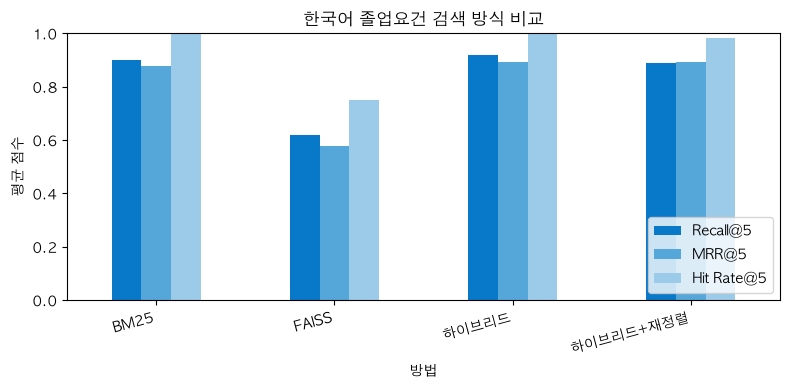

관측된 최고 Recall@5 방식: 하이브리드 (Recall@5=0.918, MRR@5=0.891)
평가 표본: 지원 가능 질의 52개. 결과는 이 평가셋과 현재 문서 추출에 한정됩니다.
결론: 본 노트북은 실제 검색 지표와 사례를 산출했으며, Gemini 제거 실험·수동 답변 검토·스캔 문서 OCR은 미완료입니다.


In [18]:
best=metric_summary.sort_values(["Recall@5","MRR@5"],ascending=False).iloc[0]
fig,ax=plt.subplots(figsize=(8,4))
metric_summary.set_index("방법")[["Recall@5","MRR@5","Hit Rate@5"]].plot(kind="bar",ax=ax,color=["#0878C9","#55A6D9","#9BCBE8"])
ax.set_ylim(0,1); ax.set_ylabel("평균 점수"); ax.set_title("한국어 졸업요건 검색 방식 비교"); ax.legend(loc="lower right"); plt.xticks(rotation=15,ha="right"); plt.tight_layout(); plt.show()
print(f"관측된 최고 Recall@5 방식: {best['방법']} (Recall@5={best['Recall@5']:.3f}, MRR@5={best['MRR@5']:.3f})")
print(f"평가 표본: 지원 가능 질의 {len(answerable)}개. 결과는 이 평가셋과 현재 문서 추출에 한정됩니다.")
print("결론: 본 노트북은 실제 검색 지표와 사례를 산출했으며, Gemini 제거 실험·수동 답변 검토·스캔 문서 OCR은 미완료입니다.")

## 20. 점검 요약 — 무엇이 틀렸고 무엇을 고쳤나 (2026-11-07)

| 영역 | 점검에서 확인한 사실 | 조치 |
|---|---|---|
| 배포 | 의미 검색(torch + 다국어 MiniLM)을 켜면 최대 메모리 **약 0.9 GB**. Render Free는 512 MB | 키워드(BM25) 검색을 배포 기본값으로 분리(약 93 MB) — 25장 |
| 비교과 규칙 | JSON의 활동별 배점(경진대회 10점×3 등)이 원본 표(비교과지정 소계 26점)에 없는 값이었고, 95점 전체와 비교해 항상 미충족으로 보였음 | 원본 표 기준으로 재작성하고 데이터 일관성 테스트 추가 |
| 이미지 자료 | `졸업자격요건.png`(복수전공 34학점, 졸업논문, 교양 32학점 등)가 챗봇에 전혀 반영되지 않았음 | 수기 전사본(`image_transcriptions.json`)으로 검색·규칙에 반영(미검증 표시) |
| 학번 혼용 | 학번과 무관하게 "2023~2024학번 표에 5점"이라고 답함 | 학번별 규칙 엔진, 학번 미지정 시 되묻기 |
| 답변 근거 | 검색된 자료를 모두 출처로 표시(실제로 쓰지 않은 자료 포함), 개발자용 문구가 사용자에게 노출 | 실제로 사용한 근거만 인용, 사용자용 문구로 교체 |
| 평가 | Gemini 호출이 모두 429로 실패해 생성형 답변 평가는 **실제 답변 0건** | 규칙 기반 엔드투엔드 평가(LLM 미사용) 추가, 생성형 충실성은 미평가로 명시 |

> 이 노트북의 임베딩은 **학습·파인튜닝이 아니라** 사전학습 모델로 문장 벡터를 계산하는 추론입니다. 어떤 모델 가중치도 이 프로젝트에서 갱신하지 않았습니다.

## 21. 문서 인벤토리와 추출 품질 (갱신)

PDF는 PyMuPDF로 텍스트 층 유무를 쪽 단위로 확인하고, 텍스트가 없는 쪽은 **OCR이 필요한 쪽**으로 보고합니다. 이 환경에는 OCR 엔진(tesseract 등)이 없어 OCR은 실행하지 않았고, 이미지 자료는 눈으로 읽은 전사본으로 대체했습니다(검수 전).

In [19]:
import pymupdf
from src.document_loader import load_documents, LOAD_NOTES
recs_now, load_warnings = load_documents()
docs_dir = ROOT/"data/documents"
rows = []
for p in sorted(docs_dir.iterdir()):
    if not p.is_file() or p.name.startswith("."): continue
    name = unicodedata.normalize("NFC", p.name); mine = [r for r in recs_now if r["source"] == name]
    info = {"자료": name, "형식": p.suffix.lower().lstrip("."), "청크 수": len(mine), "전사본 청크": sum(r["transcribed"] for r in mine)}
    if p.suffix.lower() == ".pdf":
        with pymupdf.open(p) as d:
            texts = [len(pg.get_text("text").strip()) for pg in d]
            info.update({"쪽수": len(d), "텍스트 층 없는 쪽": [i + 1 for i, n in enumerate(texts) if n < 40]})
    else:
        info.update({"쪽수": 1, "텍스트 층 없는 쪽": [1]})
    info["분류"] = mine[0]["category"] if mine else "-"
    rows.append(info)
inventory = pd.DataFrame(rows)
display(inventory)
need_ocr = [(r["자료"], r["텍스트 층 없는 쪽"], r["전사본 청크"]) for r in rows if r["텍스트 층 없는 쪽"]]
print("텍스트 층이 없어 OCR이 필요한 자료/쪽 (전사본 청크 수):")
for n, pages, t in need_ocr: print(f"  - {n}: {pages}쪽 → 전사본 청크 {t}개" + (" (전사로 대체)" if t else " (규칙 JSON으로 대체)" if "2024학번" in n else " (미처리: 예시 화면 캡처)"))
print("남은 로더 경고:", load_warnings)
print("내부 처리 기록(사용자 경고 아님):", LOAD_NOTES)

,자료,형식,청크 수,전사본 청크,쪽수,텍스트 층 없는 쪽,분류
0,2024학번 졸업요건.jpeg,jpeg,1,1,1,[1],졸업요건
1,AI·빅데이터학과_20240305.pdf,pdf,5,0,1,[],학과자료
2,AI빅데이터학과 졸업여건.png,png,7,7,1,[1],졸업요건
3,AI빅데이터학과 교육과정.pdf,pdf,9,9,2,"[1, 2]",교육과정
4,다면적졸업인증제 비교과 배점 기준표.pdf,pdf,24,0,6,[],졸업요건
5,봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf,pdf,22,0,10,[6],봉사학습
6,졸업자격요건.png,png,9,9,1,[1],졸업요건
7,학과 봉사학습 지도 가이드라인(조교ver).pdf,pdf,22,0,10,[],봉사학습


텍스트 층이 없어 OCR이 필요한 자료/쪽 (전사본 청크 수):
  - 2024학번 졸업요건.jpeg: [1]쪽 → 전사본 청크 1개 (전사로 대체)
  - AI빅데이터학과 졸업여건.png: [1]쪽 → 전사본 청크 7개 (전사로 대체)
  - AI빅데이터학과 교육과정.pdf: [1, 2]쪽 → 전사본 청크 9개 (전사로 대체)
  - 봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf: [6]쪽 → 전사본 청크 0개 (미처리: 예시 화면 캡처)
  - 졸업자격요건.png: [1]쪽 → 전사본 청크 9개 (전사로 대체)
남은 로더 경고: ['봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf 6쪽: 이미지 또는 스캔 페이지로 확인되어 문서 인식(OCR)이 필요합니다.']
내부 처리 기록(사용자 경고 아님): ['봉사활동 등록 가이드라인 및 자주묻는질문(220818ver).pdf 7쪽: 같은 자료의 중복 청크를 제외했습니다.']


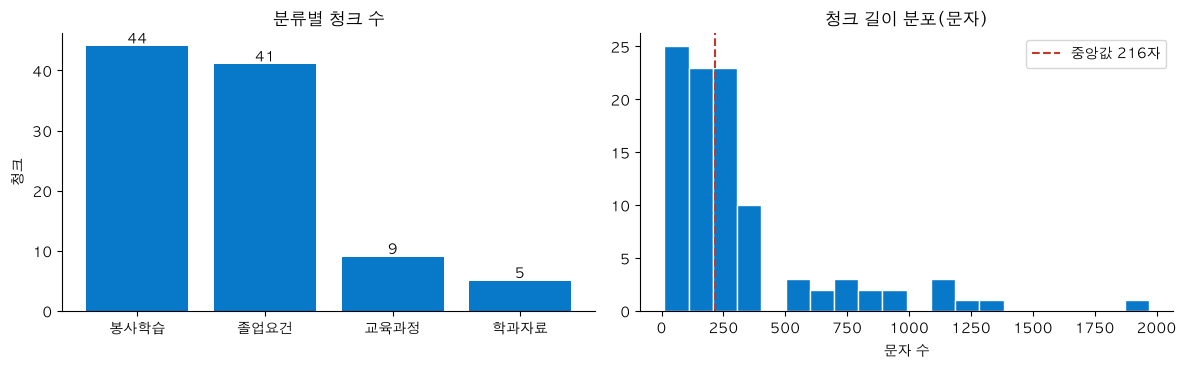

청크 99개 · 길이 최소/중앙/최대 11/216/1970자 · 학번 라벨이 있는 청크 17개 · 다른 자료와 본문이 같은 청크 7개(삭제하지 않고 duplicate_of 로 표시)
보존 메타데이터: ['admission_year', 'admission_years', 'category', 'chunk_id', 'department', 'document_date', 'duplicate_of', 'page', 'section', 'source', 'text', 'title', 'transcribed']


In [20]:
lengths = pd.Series([len(r["text"]) for r in recs_now])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cat = pd.Series([r["category"] for r in recs_now]).value_counts()
axes[0].bar(cat.index, cat.values, color="#0878C9"); axes[0].set_title("분류별 청크 수"); axes[0].set_ylabel("청크")
for i, v in enumerate(cat.values): axes[0].text(i, v + 0.5, str(v), ha="center")
axes[1].hist(lengths, bins=20, color="#0878C9", edgecolor="white"); axes[1].axvline(lengths.median(), color="#c0392b", ls="--", label=f"중앙값 {lengths.median():.0f}자")
axes[1].set_title("청크 길이 분포(문자)"); axes[1].set_xlabel("문자 수"); axes[1].legend()
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
dup = [r for r in recs_now if r["duplicate_of"]]
yr = sum(1 for r in recs_now if r["admission_years"])
print(f"청크 {len(recs_now)}개 · 길이 최소/중앙/최대 {lengths.min()}/{lengths.median():.0f}/{lengths.max()}자 · 학번 라벨이 있는 청크 {yr}개 · 다른 자료와 본문이 같은 청크 {len(dup)}개(삭제하지 않고 duplicate_of 로 표시)")
print("보존 메타데이터:", sorted(recs_now[0].keys()))

## 22. 검색 방식 비교 (실제 실험 결과)

`scripts/run_retrieval_experiments.py` 가 `data/evaluation/questions.json` 의 **답변 가능 + 라벨 있는 질문**으로 각 방식을 평가하고 `data/evaluation/results/experiment_*.csv` 로 저장합니다. 관련성 라벨은 (자료명, 쪽) 단위입니다. 차이가 우연인지 보려고 질문 단위 부트스트랩(95% 신뢰구간)을 함께 계산했습니다.

**주의:** 질문 수가 52개로 작고, 검색 규칙을 다듬는 동안 같은 질문 집합을 반복해서 봤습니다. 따라서 아래 수치는 *개발 집합 성능*이며 새 질문에서는 더 낮을 수 있습니다.

,config,recall@1,recall@3,recall@5,precision@5,mrr@5,latency_ms
0,bm25,0.584,0.804,0.900,0.442,0.878,0.396
1,bm25+anchors(promote),0.584,0.814,0.916,0.454,0.878,0.394
2,bm25+rerank,0.584,0.804,0.900,0.442,0.878,0.492
3,dense,0.314,0.512,0.617,0.323,0.576,14.280
4,hybrid,0.584,0.803,0.893,0.438,0.886,14.429
5,hybrid+rerank,0.584,0.801,0.887,0.450,0.891,14.667
6,hybrid+anchors,0.584,0.812,0.919,0.431,0.891,15.175
7,rrf,0.531,0.709,0.846,0.415,0.812,14.541


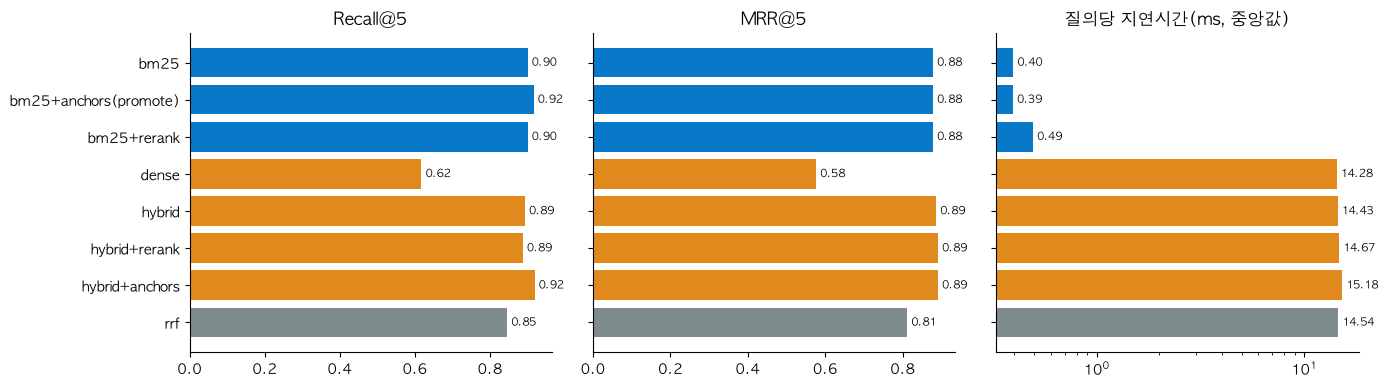

In [21]:
RES = ROOT/"data/evaluation/results"
RUN_EXPERIMENTS = False   # True 로 바꾸면 스크립트를 다시 실행합니다(의미 검색 모델 로딩 포함 수 분 소요).
if RUN_EXPERIMENTS:
    import subprocess; subprocess.run([sys.executable, str(ROOT/"scripts/run_retrieval_experiments.py")], check=True, cwd=ROOT)
summ = pd.read_csv(RES/"experiment_retrieval_summary.csv")
order = ["bm25", "bm25+anchors(promote)", "bm25+rerank", "dense", "hybrid", "hybrid+rerank", "hybrid+anchors", "rrf"]
summ = summ[summ["config"].isin(order)].set_index("config").loc[order].reset_index()
display(summ[["config", "recall@1", "recall@3", "recall@5", "precision@5", "mrr@5", "latency_ms"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ["#0878C9" if c.startswith("bm25") else "#e08a1e" if c in ("dense", "hybrid", "hybrid+rerank", "hybrid+anchors") else "#7f8c8d" for c in summ["config"]]
for ax, col, title in zip(axes, ["recall@5", "mrr@5", "latency_ms"], ["Recall@5", "MRR@5", "질의당 지연시간(ms, 중앙값)"]):
    ax.barh(summ["config"], summ[col], color=colors); ax.set_title(title); ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False)
    for i, v in enumerate(summ[col]): ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([]); axes[2].set_xscale("log")
plt.tight_layout(); plt.show()

,a,b,metric,mean_diff,ci95_low,ci95_high,significant,n_questions
0,hybrid,bm25,recall@5,-0.007,-0.062,0.041,False,52
1,rrf,bm25,recall@5,-0.054,-0.122,0.006,False,52
2,dense,bm25,recall@5,-0.283,-0.404,-0.170,True,52
3,rrf,hybrid,recall@5,-0.047,-0.090,-0.012,True,52
4,hybrid+rerank,hybrid,recall@5,-0.006,-0.029,0.012,False,52
5,bm25+anchors(filter),bm25,recall@5,0.016,0.000,0.042,False,52
6,bm25+anchors(promote),bm25,recall@5,0.016,0.000,0.042,False,52
7,hybrid+anchors,hybrid,recall@5,0.026,0.000,0.070,False,52
8,bm25+rerank,bm25,recall@5,0.000,0.000,0.000,False,52


significant=True 는 95% 신뢰구간이 0을 포함하지 않는 경우입니다. 이 52개 질문에서 BM25 와 하이브리드의 Recall@5 차이는 우연 범위입니다.


config,bm25,dense,hybrid
category,,,
계산,1.00,1.00,1.00
교육과정,1.00,1.00,1.00
미확인,1.00,1.00,1.00
봉사학습,0.76,0.54,0.73
비교과,0.92,0.32,0.89
전공,1.00,1.00,1.00
학번 차이,0.90,0.50,0.90
학점,0.96,0.92,1.00


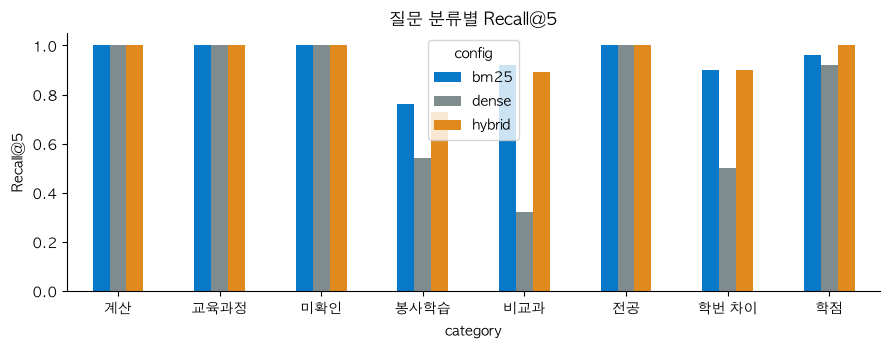

In [22]:
sig = pd.read_csv(RES/"experiment_significance.csv")
display(sig.round(3))
print("significant=True 는 95% 신뢰구간이 0을 포함하지 않는 경우입니다. 이 52개 질문에서 BM25 와 하이브리드의 Recall@5 차이는 우연 범위입니다.")
cat = pd.read_csv(RES/"experiment_retrieval_by_category.csv")
pv = cat[cat["config"].isin(["bm25", "hybrid", "dense"])].pivot(index="category", columns="config", values="recall@5").round(2)
display(pv)
ax = pv.plot.bar(figsize=(9, 3.6), color=["#0878C9", "#7f8c8d", "#e08a1e"]); ax.set_ylabel("Recall@5"); ax.set_title("질문 분류별 Recall@5"); ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 23. 청크 크기·겹침과 색인 문맥 헤더 실험

앞 장의 04장은 청크 크기를 **가상 계산**으로만 비교했습니다. 여기서는 세 가지 설정으로 실제로 문서를 다시 청킹하고 색인을 만들어 같은 질문으로 평가했습니다. 또한 청크 앞에 자료명·학과·학번·절 제목을 붙여 색인하는 방식(문맥 헤더)을 켜고 끈 결과를 비교했습니다.

In [23]:
chunk_df = pd.read_csv(RES/"experiment_chunk_size.csv"); display(chunk_df[["method", "chunk_size", "overlap", "chunks", "recall@3", "recall@5", "precision@5", "mrr@5"]].round(3))
hdr = pd.read_csv(RES/"experiment_header_ablation.csv"); display(hdr.round(3))
print("해석: 청크 크기에 따른 Recall@5 차이는 0.01 안팎으로 구분되지 않습니다 → 기존 1100/120 유지. 문맥 헤더는 Recall@1 을 올리고 Recall@3·5 를 내려 득실이 엇갈려 기본값을 끔(RETRIEVAL_HEADERS=1 로 켤 수 있음).")
print("유의: 색인 방식들은 서로 영향을 줍니다(질의 불용어 제거를 넣기 전에는 헤더가 +0.05 이득이었으나 넣은 뒤에는 사라짐).")

,method,chunk_size,overlap,chunks,recall@3,recall@5,precision@5,mrr@5
0,bm25,600,80,107,0.794,0.896,0.446,0.875
1,hybrid,600,80,107,0.812,0.903,0.438,0.886
2,bm25,1100,120,99,0.804,0.900,0.442,0.878
3,hybrid,1100,120,99,0.803,0.893,0.438,0.886
4,bm25,1800,200,98,0.804,0.900,0.442,0.878
5,hybrid,1800,200,98,0.803,0.897,0.442,0.886


,contextual_header,method,recall@1,precision@1,recall@3,precision@3,recall@5,precision@5,mrr@5
0,False,bm25,0.584,0.808,0.804,0.564,0.900,0.442,0.878
1,False,dense,0.314,0.481,0.512,0.378,0.617,0.323,0.576
2,False,hybrid,0.584,0.808,0.803,0.538,0.893,0.438,0.886
3,False,rrf,0.531,0.731,0.709,0.474,0.846,0.415,0.812
4,True,bm25,0.612,0.846,0.776,0.564,0.870,0.462,0.887
5,True,dense,0.319,0.462,0.571,0.397,0.626,0.323,0.577
6,True,hybrid,0.588,0.827,0.826,0.558,0.859,0.465,0.897
7,True,rrf,0.537,0.712,0.664,0.494,0.754,0.423,0.786


해석: 청크 크기에 따른 Recall@5 차이는 0.01 안팎으로 구분되지 않습니다 → 기존 1100/120 유지. 문맥 헤더는 Recall@1 을 올리고 Recall@3·5 를 내려 득실이 엇갈려 기본값을 끔(RETRIEVAL_HEADERS=1 로 켤 수 있음).
유의: 색인 방식들은 서로 영향을 줍니다(질의 불용어 제거를 넣기 전에는 헤더가 +0.05 이득이었으나 넣은 뒤에는 사라짐).


## 24. 엔드투엔드 답변 동작 평가 (LLM 미사용)

`scripts/run_answer_evaluation.py` 는 60개 질문 전체에 대해 챗봇 파이프라인(`respond`)을 호출하고 **기대 동작**을 규칙으로 검사합니다: 정상 답변, 학번 되묻기, 답변 거부, 자료 충돌 표시, 다른 학번 값 혼용 금지. 기대 사실은 숫자/키워드 포함 여부, 인용은 (자료, 쪽) 일치 여부로 판정합니다.

한계: 사실 확인은 문자열 기반이라 **서술형 라벨은 정답이어도 실패로 계산**될 수 있고(예: Q18), 생성형 답변의 충실성·정확성은 이 평가가 다루지 않습니다.

In [24]:
out = {}
for b in ("bm25", "hybrid"):
    s = pd.read_csv(RES/f"answer_eval_extractive_{b}_summary.csv"); s.insert(0, "backend", b); out[b] = s
    ov = json.loads((RES/f"answer_eval_extractive_{b}_overall.json").read_text(encoding="utf-8")); print(b, ov)
display(pd.concat(out.values()).round(3))
pq = pd.read_csv(RES/"answer_eval_extractive_bm25_per_question.csv")
fail = pq[~pq["passed"]][["question_id", "expected_behavior", "outcome", "fact_recall", "citation_hit", "question"]]
print(f"BM25 기준 실패 {len(fail)}건 (소프트 통과 포함 시 {int((~pq['soft_passed']).sum())}건):"); display(fail)

bm25 {'n': 60, 'passed': 50, 'pass_rate': 0.833, 'soft_pass_rate': 0.867, 'p95_latency_ms': 7.64, 'backend': 'bm25'}
hybrid {'n': 60, 'passed': 50, 'pass_rate': 0.833, 'soft_pass_rate': 0.867, 'p95_latency_ms': 23.0, 'backend': 'hybrid'}


,backend,expected_behavior,n,passed,pass_rate,soft_pass_rate,fact_recall,citation_hit,citation_precision,median_latency_ms
0,bm25,answer,40,32,0.800,0.8,0.833,0.975,0.855,1.155
1,bm25,answer_with_caveat,6,6,1.000,1.0,1.000,1.000,1.000,0.085
2,bm25,answer_with_conflict,2,2,1.000,1.0,1.000,1.000,1.000,0.080
3,bm25,calculate,1,1,1.000,1.0,1.000,1.000,0.500,0.210
4,bm25,clarify_year,3,3,1.000,1.0,NaN,NaN,NaN,0.080
5,bm25,insufficient,7,5,0.714,1.0,0.000,NaN,NaN,3.400
6,bm25,no_year_mixing,1,1,1.000,1.0,NaN,1.000,1.000,0.090
0,hybrid,answer,40,32,0.800,0.8,0.833,0.975,0.855,8.790
1,hybrid,answer_with_caveat,6,6,1.000,1.0,1.000,1.000,1.000,0.160
2,hybrid,answer_with_conflict,2,2,1.000,1.0,1.000,1.000,1.000,0.105


BM25 기준 실패 10건 (소프트 통과 포함 시 8건):


,question_id,expected_behavior,outcome,fact_recall,citation_hit,question
13,Q14,answer,hedged,1.000000,True,2024학번 코딩역량인증제 배점은 몇 점인가요?
15,Q16,answer,hedged,0.000000,True,2024학번 다면적 졸업인증제 비교과 배점 기준표는 무엇을 설명하나요?
17,Q18,answer,answered,0.000000,True,외국인 유학생은 봉사학습 이수 대상인가요?
19,Q20,answer,answered,0.000000,True,자율봉사는 포털에서 어떻게 신청하나요?
20,Q21,answer,refused,0.000000,False,봉사활동 증빙은 어느 기관 인증서를 사용할 수 있나요?
24,Q25,answer,answered,0.000000,True,봉사학습을 완료하지 못하면 졸업할 수 있나요?
37,Q38,answer,answered,0.000000,True,졸업에 봉사활동이 필요한가요?
44,Q45,answer,hedged,0.333333,True,2019학번 대학공통 필수 항목은 무엇인가요?
56,Q57,insufficient,hedged,NaN,NaN,교환학생 지원 자격은 무엇인가요?
57,Q58,insufficient,hedged,NaN,NaN,복수전공 신청은 언제 할 수 있나요?


,n,passed,pass_rate
question_type,,,
ambiguous_year,3,3,1.00
calculation,1,1,1.00
conflicting,2,2,1.00
factual,46,38,0.83
injection,1,1,1.00
out_of_scope,1,0,0.00
unanswerable,5,4,0.80
year_trap,1,1,1.00


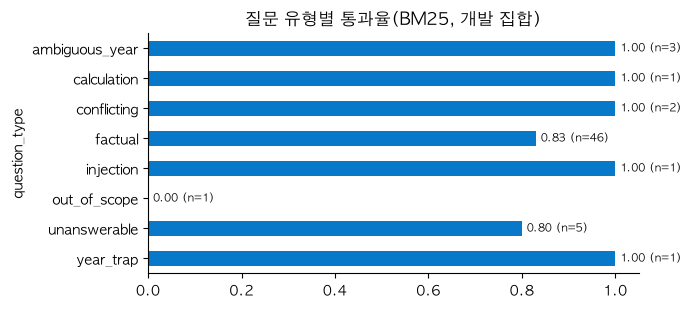

오류 분석: 실패 대부분은 (1) 봉사학습 안내문처럼 모든 FAQ가 같은 단어를 공유해 BM25 순위가 흔들리는 경우, (2) '신청'처럼 흔한 단어로 질문이 짧은 경우, (3) 서술형 라벨의 문자열 판정 한계입니다. 다른 학번의 값 등 금지 사실이 답변에 나온 경우는 0건이었고, 발췌 방식이라 생성 문장이 없어 지어낸 사실은 없었습니다. 다만 Q20·Q25·Q38처럼 질문에 직접 답하지 않는 발췌가 보인 사례가 있고, 실패는 거부(Q21)·약한 근거 표시·엉뚱한 발췌 형태로 나타났습니다.


In [25]:
ct = pq.groupby("question_type").agg(n=("passed", "size"), passed=("passed", "sum")); ct["pass_rate"] = (ct["passed"] / ct["n"]).round(2)
display(ct)
ax = ct["pass_rate"].plot.barh(figsize=(7, 3.2), color="#0878C9"); ax.set_xlim(0, 1.05); ax.set_title("질문 유형별 통과율(BM25, 개발 집합)"); ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False)
for i, (v, n) in enumerate(zip(ct["pass_rate"], ct["n"])): ax.text(v + 0.01, i, f"{v:.2f} (n={n})", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("오류 분석: 실패 대부분은 (1) 봉사학습 안내문처럼 모든 FAQ가 같은 단어를 공유해 BM25 순위가 흔들리는 경우, (2) '신청'처럼 흔한 단어로 질문이 짧은 경우, (3) 서술형 라벨의 문자열 판정 한계입니다. 다른 학번의 값 등 금지 사실이 답변에 나온 경우는 0건이었고, 발췌 방식이라 생성 문장이 없어 지어낸 사실은 없었습니다. 다만 Q20·Q25·Q38처럼 질문에 직접 답하지 않는 발췌가 보인 사례가 있고, 실패는 거부(Q21)·약한 근거 표시·엉뚱한 발췌 형태로 나타났습니다.")

## 25. 자원 측정과 Render Free 적합성

`scripts/measure_resources.py` 가 구성마다 **깨끗한 하위 프로세스**에서 최대 메모리(RSS)와 지연시간을 측정합니다(macOS 측정값). Render Free는 512 MB RAM / 0.1 CPU 이며, 위 값에는 Streamlit 서버 자체의 메모리가 더해집니다.

,config,after_import_mb,index_load_s,after_index_mb,backend,median_query_ms,p95_query_ms,peak_rss_mb,torch_loaded
0,bm25 (Render 권장),89.4,0.01,92.5,bm25,2.0,6.4,92.6,False
1,hybrid (BM25 + 의미 검색),88.7,9.79,885.0,hybrid,15.8,22.4,885.0,True


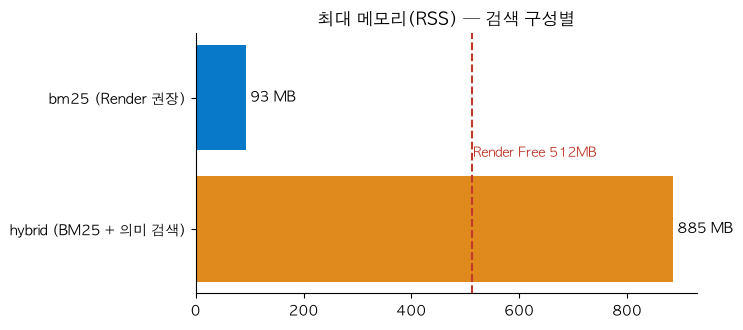

결론: 의미 검색 구성은 모델 적재만으로 약 0.9GB 이고 로딩에 약 10초가 걸려 Render Free(512MB)에서 실행할 수 없습니다. 같은 질문 집합에서 정확도 이득은 통계적으로 구분되지 않았으므로(22장) BM25 구성을 배포 기본값으로 선택했습니다.


In [26]:
res = pd.read_csv(RES/"resource_usage.csv"); display(res)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(res["config"], res["peak_rss_mb"], color=["#0878C9", "#e08a1e"]); ax.axvline(512, color="#c0392b", ls="--"); ax.text(515, 0.45, "Render Free 512MB", color="#c0392b", fontsize=9)
for i, v in enumerate(res["peak_rss_mb"]): ax.text(v + 8, i, f"{v:.0f} MB", va="center")
ax.set_title("최대 메모리(RSS) — 검색 구성별"); ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
print("결론: 의미 검색 구성은 모델 적재만으로 약 0.9GB 이고 로딩에 약 10초가 걸려 Render Free(512MB)에서 실행할 수 없습니다. 같은 질문 집합에서 정확도 이득은 통계적으로 구분되지 않았으므로(22장) BM25 구성을 배포 기본값으로 선택했습니다.")

## 26. 최종 구성과 선택 이유, 남은 한계

**배포 구성(Render Free):** BM25(`rank-bm25`, 한국어 어절 + 2글자 토큰, 질의 불용어·조사 처리, 학번 필터) → 근거 평가(핵심어 포함도, 가장 드문 핵심어 필수) → 학점·점수 질문은 구조화 규칙 엔진 → (선택) Gemini 요약 → 실패 시 자료 원문 발췌. 청크 1100자/겹침 120자, Top-5, 재정렬 없음, 의미 검색 없음.

**선택 이유:** (1) 의미 검색·RRF·재정렬은 BM25 대비 유의한 이득이 없었고(22장), (2) 메모리·로딩 시간 비용이 크며(25장), (3) 질의당 지연이 2~6ms로 충분합니다. 의미 검색은 `RETRIEVAL_BACKEND=auto` 로 로컬/대형 인스턴스에서 계속 사용할 수 있습니다.

**남은 한계**
- 평가 질문 52~60개, 같은 집합으로 반복 개선 → 새 질문에서의 성능은 이보다 낮을 수 있음.
- 이미지·스캔 자료는 OCR이 아니라 **수기 전사**(검수 전). `졸업자격요건.png`는 학과명이 없어 AI·빅데이터학과 기준인지 확정할 수 없음.
- Gemini 생성은 실제 성공 응답을 한 번도 확인하지 못함(429 → 504). 충실성·정답성 평가는 미실시.
- 학번별 전공·교양 학점 표는 2024학번만 있음. 다른 학번은 학과 미표기 표로 부분 안내.
- BM25는 FAQ처럼 같은 단어를 공유하는 문서에서 순위가 흔들림.